In [49]:
import pandas as pd
df = pd.read_csv("/content/sample_data/houston_homes_50000_moderate_correlation.csv")
df.head()

,City,SqFt,Beds,YearBuilt,Price
0,Tomball,2040,3,2005,196888
1,Cypress,2960,4,1982,254902
2,Pearland,3884,5,2006,433774
3,Tomball,2152,3,2014,272017
4,Spring,2316,3,1989,242367


In [50]:
len(df["City"].unique())

10

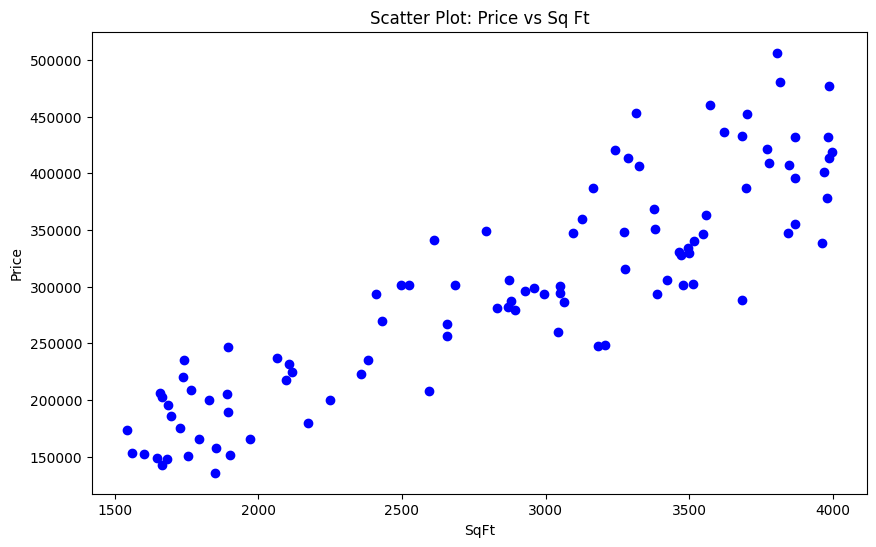

In [51]:
import matplotlib.pyplot as plt

df_sample = df.sample(n=100, random_state=42)

plt.figure(figsize=(10, 6))
plt.scatter(df_sample["SqFt"], df_sample["Price"], color="blue")
plt.title("Scatter Plot: Price vs Sq Ft")
plt.xlabel("SqFt")
plt.ylabel("Price")
plt.show()

In [52]:
df.head()

,City,SqFt,Beds,YearBuilt,Price
0,Tomball,2040,3,2005,196888
1,Cypress,2960,4,1982,254902
2,Pearland,3884,5,2006,433774
3,Tomball,2152,3,2014,272017
4,Spring,2316,3,1989,242367


In [53]:
df = pd.get_dummies(df, columns=["City"])

In [54]:
df.head()

,SqFt,Beds,YearBuilt,Price,City_Conroe,City_Cypress,City_Humble,City_Katy,City_Pearland,City_Richmond,City_Spring,City_Sugar Land,City_The Woodlands,City_Tomball
0,2040,3,2005,196888,False,False,False,False,False,False,False,False,False,True
1,2960,4,1982,254902,False,True,False,False,False,False,False,False,False,False
2,3884,5,2006,433774,False,False,False,False,True,False,False,False,False,False
3,2152,3,2014,272017,False,False,False,False,False,False,False,False,False,True
4,2316,3,1989,242367,False,False,False,False,False,False,True,False,False,False


In [55]:
X = df.drop("Price", axis=1)
y = df["Price"]

In [56]:
X

,SqFt,Beds,YearBuilt,City_Conroe,City_Cypress,City_Humble,City_Katy,City_Pearland,City_Richmond,City_Spring,City_Sugar Land,City_The Woodlands,City_Tomball
0,2040,3,2005,False,False,False,False,False,False,False,False,False,True
1,2960,4,1982,False,True,False,False,False,False,False,False,False,False
2,3884,5,2006,False,False,False,False,True,False,False,False,False,False
3,2152,3,2014,False,False,False,False,False,False,False,False,False,True
4,2316,3,1989,False,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,3453,5,2007,False,False,False,False,False,False,True,False,False,False
49996,1843,2,2020,False,False,False,False,False,False,False,True,False,False
49997,1903,2,1977,False,False,False,False,False,False,False,False,True,False
49998,1938,2,1976,False,False,False,True,False,False,False,False,False,False


In [57]:
y

,Price
0,196888
1,254902
2,433774
3,272017
4,242367
...,...
49995,371206
49996,250020
49997,181128
49998,172707


In [58]:
from sklearn.model_selection import train_test_split

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [60]:
len(X_train)

40000

In [61]:
len(X_test)

10000

In [62]:
from sklearn.linear_model import LinearRegression

In [63]:
model = LinearRegression()

In [64]:
model.fit(X_train, y_train)

LinearRegression()

In [65]:
y_pred = model.predict(X_test)

In [66]:
from sklearn.metrics import mean_squared_error, r2_score

In [67]:
# Evaluate
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))

Mean Squared Error: 1258894482.784055
R² Score: 0.8392232544670505


In [68]:
import numpy as np
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 35480.90307170965
